In [31]:
import numpy as np
import pandas as pd
import PySulfSat as ss
import matplotlib.pyplot as plt
import Thermobar as pt


In [32]:
df=ss.import_data('GorWood_Answers.xlsx', sheet_name='RightCoffs')
df['Sample_ID_Liq']='test'
# to start, cheated and worked with normalized values - might be the issue, migh tnot


We have replaced all missing liquid oxides and strings with zeros. 


In [33]:
df_thermobar=pt.import_excel(df=df)['Liqs']
df_thermobar

,SiO2_Liq,TiO2_Liq,Al2O3_Liq,FeOt_Liq,MnO_Liq,MgO_Liq,CaO_Liq,Na2O_Liq,K2O_Liq,Cr2O3_Liq,P2O5_Liq,H2O_Liq,Fe3Fet_Liq,NiO_Liq,CoO_Liq,CO2_Liq,Sample_ID_Liq
0,50.752072,0.941369,14.939118,9.209045,0.0,8.902077,12.688018,2.353423,0.214878,0,0,0.000000,0.0,0.0,0.0,0.0,test
1,50.752072,0.941369,14.939118,9.209045,0.0,8.902077,12.688018,2.353423,0.214878,0,0,0.000000,0.0,0.0,0.0,0.0,test
2,50.752072,0.941369,14.939118,9.209045,0.0,8.902077,12.688018,2.353423,0.214878,0,0,0.000000,0.0,0.0,0.0,0.0,test
3,50.752072,0.941369,14.939118,9.209045,0.0,8.902077,12.688018,2.353423,0.214878,0,0,0.000000,0.0,0.0,0.0,0.0,test
4,50.752072,0.941369,14.939118,9.209045,0.0,8.902077,12.688018,2.353423,0.214878,0,0,0.000000,0.0,0.0,0.0,0.0,test
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,53.767725,1.205509,17.500306,6.511789,0.0,2.768583,5.864084,4.474684,1.777614,0,0,6.129705,0.0,0.0,0.0,0.0,test
83,53.767725,1.205509,17.500306,6.511789,0.0,2.768583,5.864084,4.474684,1.777614,0,0,6.129705,0.0,0.0,0.0,0.0,test
84,53.767725,1.205509,17.500306,6.511789,0.0,2.768583,5.864084,4.474684,1.777614,0,0,6.129705,0.0,0.0,0.0,0.0,test
85,53.767725,1.205509,17.500306,6.511789,0.0,2.768583,5.864084,4.474684,1.777614,0,0,6.129705,0.0,0.0,0.0,0.0,test


In [54]:
pa=pt.convert_fo2_to_fe_partition(liq_comps=df_thermobar, T_K=df['T °C']+273.15, P_kbar=df['P (Gpa)']*10,
                                model="Kress1991", fo2=10**df['logfo2'], renorm=True, fo2_offset=0)
pa['Fe3Fet_Liq'].to_clipboard(excel=True)


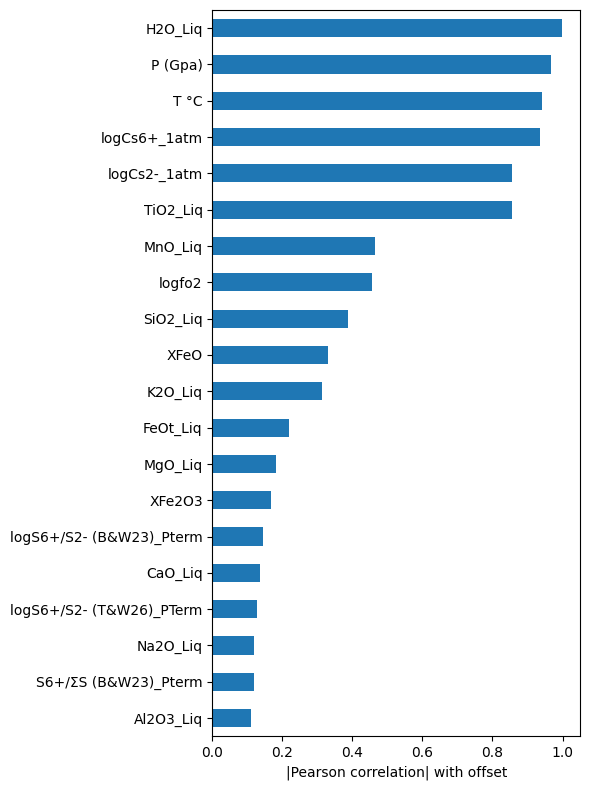

In [35]:
offset = pa['ln_XFe2FeO3_XFeO']-df['lnXFe2O3/XFeO']

# Numeric columns only
num_cols = df.select_dtypes(include='number')

corrs = num_cols.corrwith(offset)

corrs_abs = corrs.abs().sort_values(ascending=False)

plt.figure(figsize=(6, 8))
corrs_abs.head(20).sort_values().plot.barh()
plt.xlabel('|Pearson correlation| with offset')
plt.tight_layout()

Text(0, 0.5, 'gorojovsky ln_XFe2FeO3_XFeO')

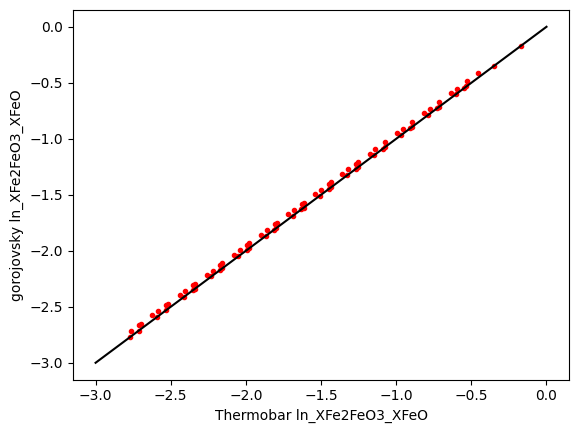

In [46]:
plt.plot(pa['ln_XFe2FeO3_XFeO'], df['lnXFe2O3/XFeO'], '.r')
plt.plot([-3, 0], [-3, 0], '-k')
plt.xlabel('Thermobar ln_XFe2FeO3_XFeO')
plt.ylabel('gorojovsky ln_XFe2FeO3_XFeO')

In [43]:
pt.calculate_hydrous_mol_proportions_liquid(df_thermobar).to_clipboard(excel=True)

## Lets try giving it Fe3FeT instead of logfo2

In [6]:
bench_Fe3FeT_input=ss.calculate_GW2026_S6St(df=df, Fe3Fet_Liq=df['Fe3FeT'], T_K=df['T °C']+273.15, P_kbar=df['P (Gpa)']*10)
bench_Fe3FeT_input.head()

overwriting Fe3Fet_Liq to that specified in the function input


,LogCs2_1atm,LogCS6_1atm,logS6S2_1atm,S6St_1atm,logS6S2_TW26,S6St_TW26,logS6S2_MC25,S6St_MC25,logS6S2_BW23,S6St_BW23,...,S6+/ΣS (B&W23)_Pterm,Fe3FeT,logfo2,lnXFe2O3/XFeO,logXFe2O3/XFeO,XFe2O3/XFeO,XFeO,XFe2O3,Fe3+/ΣFe,Sample_ID_Liq
0,-6.146547,10.810528,-5.515963,0.000003,-5.516046,0.000003,-5.516014,0.000003,-5.516054,0.000003,...,0.000003,0.117154,-11.234237,-2.713108,-1.178076,0.066330,0.069922,0.004638,0.117123,test
1,-6.158614,10.810528,-4.705281,0.000020,-4.705363,0.000020,-4.705331,0.000020,-4.705372,0.000020,...,0.000020,0.137153,-10.834237,-2.532585,-1.099690,0.079453,0.068338,0.005430,0.137118,test
2,-6.172369,10.810528,-3.893107,0.000128,-3.893190,0.000128,-3.893157,0.000128,-3.893198,0.000128,...,0.000131,0.159948,-10.434237,-2.352063,-1.021304,0.095173,0.066533,0.006332,0.159908,test
3,-6.187918,10.810528,-3.079349,0.000832,-3.079431,0.000832,-3.079399,0.000832,-3.079439,0.000832,...,0.000855,0.185716,-10.034237,-2.171540,-0.942918,0.114002,0.064493,0.007352,0.185670,test
4,-6.205333,10.810528,-2.263944,0.005416,-2.264026,0.005415,-2.263994,0.005416,-2.264035,0.005415,...,0.005592,0.214574,-9.634237,-1.991017,-0.864532,0.136556,0.062208,0.008495,0.214524,test


In [7]:
bench_logfo2_input=ss.calculate_GW2026_S6St(df=df, logfo2=df['logfo2'], T_K=df['T °C']+273.15, P_kbar=df['P (Gpa)']*10)
bench_logfo2_input.head()

,LogCs2_1atm,LogCS6_1atm,logS6S2_1atm,S6St_1atm,logS6S2_TW26,S6St_TW26,logS6S2_MC25,S6St_MC25,logS6S2_BW23,S6St_BW23,...,S6+/ΣS (B&W23)_Pterm,Fe3FeT,logfo2,lnXFe2O3/XFeO,logXFe2O3/XFeO,XFe2O3/XFeO,XFeO,XFe2O3,Fe3+/ΣFe,Sample_ID_Liq
0,-6.146448,10.810528,-5.511497,0.000003,-5.511580,0.000003,-5.511547,0.000003,-5.511588,0.000003,...,0.000003,0.117154,-11.234237,-2.713108,-1.178076,0.066330,0.069922,0.004638,0.117123,test
1,-6.158501,10.810528,-4.699444,0.000020,-4.699526,0.000020,-4.699494,0.000020,-4.699535,0.000020,...,0.000020,0.137153,-10.834237,-2.532585,-1.099690,0.079453,0.068338,0.005430,0.137118,test
2,-6.172241,10.810528,-3.885704,0.000130,-3.885787,0.000130,-3.885755,0.000130,-3.885795,0.000130,...,0.000131,0.159948,-10.434237,-2.352063,-1.021304,0.095173,0.066533,0.006332,0.159908,test
3,-6.187774,10.810528,-3.070171,0.000850,-3.070254,0.000850,-3.070222,0.000850,-3.070262,0.000850,...,0.000855,0.185716,-10.034237,-2.171540,-0.942918,0.114002,0.064493,0.007352,0.185670,test
4,-6.205172,10.810528,-2.252773,0.005557,-2.252856,0.005556,-2.252823,0.005556,-2.252864,0.005555,...,0.005592,0.214574,-9.634237,-1.991017,-0.864532,0.136556,0.062208,0.008495,0.214524,test


## Benchmarking with specified deltaQFM

In [8]:
bench=ss.calculate_GW2026_S6St(df=df, T_K=df['T °C']+273.15, P_kbar=df['P (Gpa)']*10, deltaQFM=df['ΔFMQ'])
bench.head()

,LogCs2_1atm,LogCS6_1atm,logS6S2_1atm,S6St_1atm,logS6S2_TW26,S6St_TW26,logS6S2_MC25,S6St_MC25,logS6S2_BW23,S6St_BW23,...,S6+/ΣS (B&W23)_Pterm,Fe3FeT,logfo2,lnXFe2O3/XFeO,logXFe2O3/XFeO,XFe2O3/XFeO,XFeO,XFe2O3,Fe3+/ΣFe,Sample_ID_Liq
0,-6.146509,10.810528,-5.507136,0.000003,-5.507218,0.000003,-5.507186,0.000003,-5.507226,0.000003,...,0.000003,0.117154,-11.234237,-2.713108,-1.178076,0.066330,0.069922,0.004638,0.117123,test
1,-6.158571,10.810528,-4.695074,0.000020,-4.695156,0.000020,-4.695124,0.000020,-4.695164,0.000020,...,0.000020,0.137153,-10.834237,-2.532585,-1.099690,0.079453,0.068338,0.005430,0.137118,test
2,-6.172320,10.810528,-3.881325,0.000131,-3.881407,0.000131,-3.881375,0.000131,-3.881416,0.000131,...,0.000131,0.159948,-10.434237,-2.352063,-1.021304,0.095173,0.066533,0.006332,0.159908,test
3,-6.187862,10.810528,-3.065782,0.000859,-3.065864,0.000859,-3.065832,0.000859,-3.065873,0.000859,...,0.000855,0.185716,-10.034237,-2.171540,-0.942918,0.114002,0.064493,0.007352,0.185670,test
4,-6.205271,10.810528,-2.248374,0.005613,-2.248456,0.005612,-2.248424,0.005612,-2.248464,0.005612,...,0.005592,0.214574,-9.634237,-1.991017,-0.864532,0.136556,0.062208,0.008495,0.214524,test


Text(0, 0.5, 'My S6/St over their S6/St')

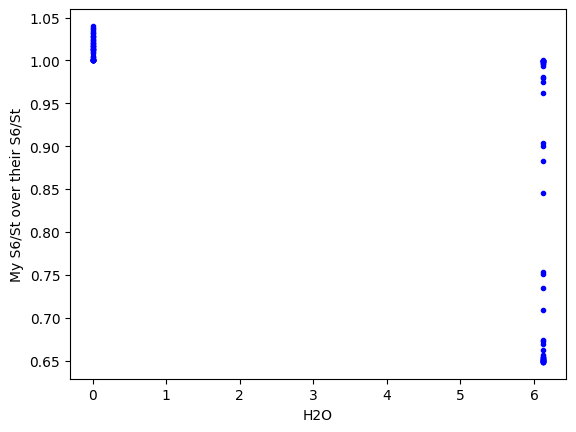

In [53]:
#plt.plot(df['H2O_Liq'], pa['ln_XFe2FeO3_XFeO']/df['lnXFe2O3/XFeO'], '.r')
plt.plot(df['H2O_Liq'], bench['S6St_1atm']/bench_Fe3FeT_input['S6St_1atm'], '.b', label='Fe3Fet input')
plt.xlabel('H2O')
plt.ylabel('My S6/St over their S6/St')

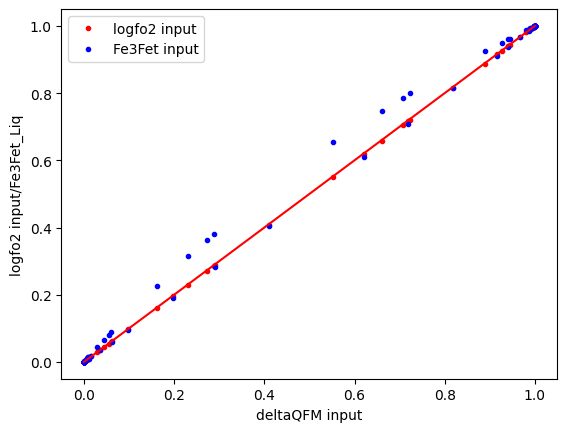

In [9]:
plt.plot(bench['S6St_1atm'], bench_logfo2_input['S6St_1atm'], '.r', label='logfo2 input')
plt.plot(bench['S6St_1atm'], bench_Fe3FeT_input['S6St_1atm'], '.b', label='Fe3Fet input')
plt.xlabel('deltaQFM input')
plt.ylabel('logfo2 input/Fe3Fet_Liq')
plt.plot([0, 1], [0, 1], '-r')
plt.legend()

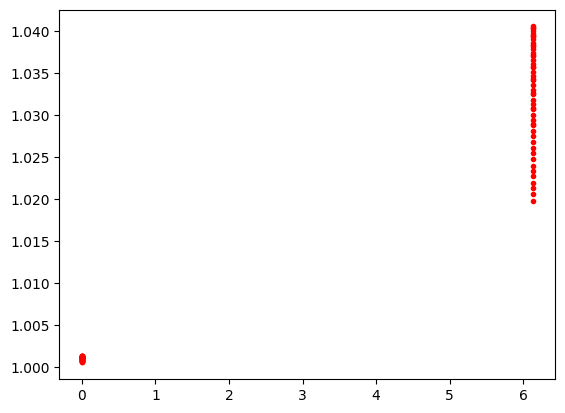

In [44]:
plt.plot(df['H2O_Liq'], df['Fe3FeT']/pa['Fe3Fet_Liq'], '.r')


In [ ]:
plt.plot()

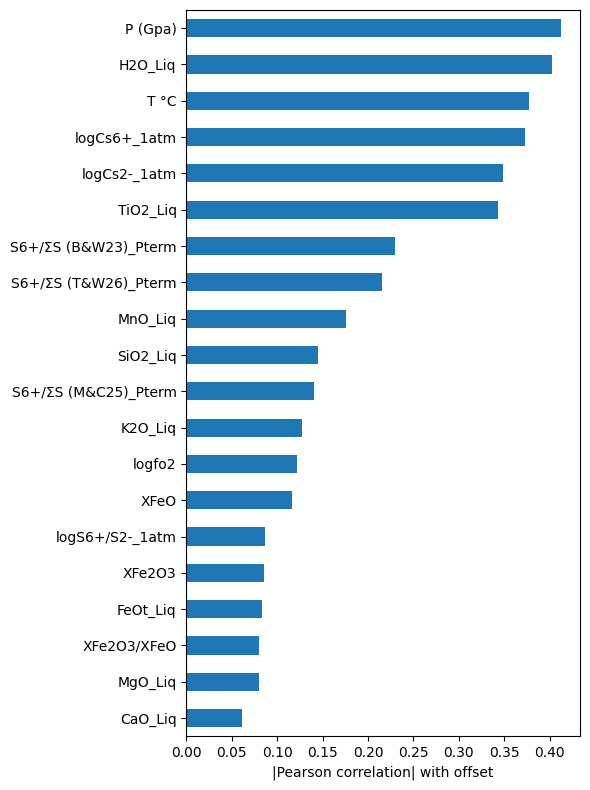

In [24]:
offset = bench['S6St_1atm'] - bench_Fe3FeT_input['S6St_1atm']

# Numeric columns only
num_cols = df.select_dtypes(include='number')

corrs = num_cols.corrwith(offset)

corrs_abs = corrs.abs().sort_values(ascending=False)

plt.figure(figsize=(6, 8))
corrs_abs.head(20).sort_values().plot.barh()
plt.xlabel('|Pearson correlation| with offset')
plt.tight_layout()

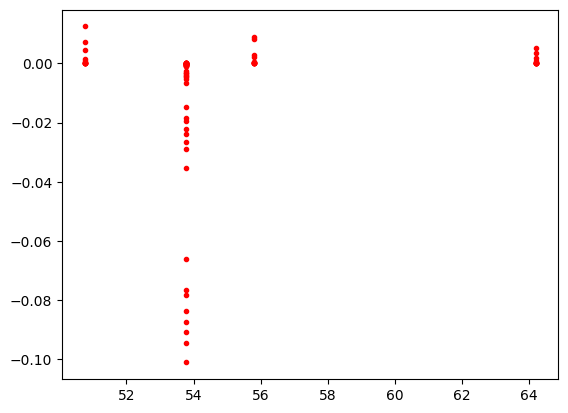

In [23]:
plt.plot(df['SiO2_Liq'], bench['S6St_1atm']-bench_Fe3FeT_input['S6St_1atm'], '.r' )

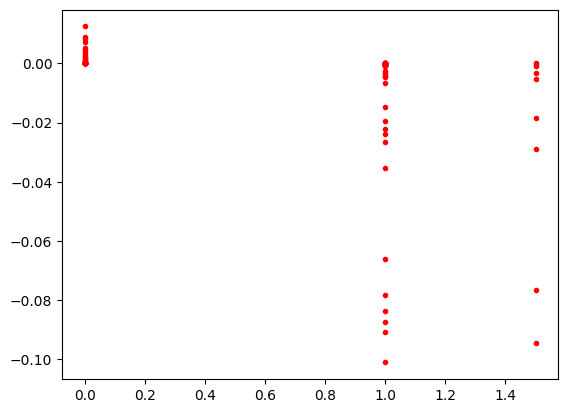

In [12]:
plt.plot(df['P (Gpa)'], bench['S6St_1atm']-bench_Fe3FeT_input['S6St_1atm'], '.r' )

## TW26 pressure term

{'R2': 1.0,
 'RMSE': 0.00023,
 'RMSE_num': 0.00023224954092559194,
 'P_val': 0.0,
 'Median': 0.0,
 'Mean': 4e-05,
 'Int': array([3.20010903e-05]),
 'Grad': array([1.00002101]),
 'Grad_err': 6e-05,
 'x_pred': array([[3.09897009e-06],
        [2.01037861e-05],
        [1.30913609e-04],
        [8.55499007e-04],
        [5.59205044e-03],
        [3.57676895e-02],
        [1.97257907e-01],
        [6.20396760e-01],
        [9.16025243e-01],
        [9.86490136e-01],
        [9.97962625e-01],
        [9.99696118e-01],
        [9.99954750e-01],
        [1.56119273e-06],
        [9.95707879e-06],
        [6.35996532e-05],
        [4.06785787e-04],
        [2.60147329e-03],
        [1.64706224e-02],
        [9.72355405e-02],
        [4.09646945e-01],
        [8.17421515e-01],
        [9.66581050e-01],
        [9.94681730e-01],
        [9.99174350e-01],
        [9.99872333e-01],
        [1.11194114e-06],
        [6.95508488e-06],
        [4.34570384e-05],
        [2.71194609e-04],
        [1.68

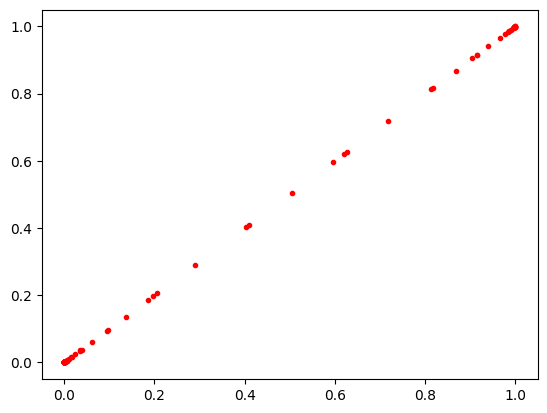

In [13]:
theirname='S6+/ΣS (T&W26)_Pterm'
myname='S6St_TW26'
plt.plot(df[theirname], bench[myname], '.r')
import Thermobar as pt
#plt.plot([-7, 4], [-7, 4], '-r')
pt.calculate_R2(df[theirname], bench[myname])



{'R2': 1.0,
 'RMSE': 0.00121,
 'RMSE_num': 0.0012067097027680732,
 'P_val': 0.0,
 'Median': 0.00063,
 'Mean': 0.00066,
 'Int': array([0.00057749]),
 'Grad': array([0.99993952]),
 'Grad_err': 4e-05,
 'x_pred': array([[-5.50878127],
        [-4.69671341],
        [-3.88295834],
        [-3.06740879],
        [-2.24999351],
        [-1.43069079],
        [-0.60954162],
        [ 0.21333961],
        [ 1.03775869],
        [ 1.86344177],
        [ 2.69004335],
        [ 3.51716237],
        [ 4.34436519],
        [-5.8065428 ],
        [-5.00186373],
        [-4.19651763],
        [-3.39045753],
        [-2.58364935],
        [-1.77607733],
        [-0.96774942],
        [-0.15870209],
        [ 0.65099646],
        [ 1.46124548],
        [ 2.27191378],
        [ 3.08284528],
        [ 3.8938675 ],
        [-5.95391772],
        [-5.15769455],
        [-4.361921  ],
        [-3.56660115],
        [-2.77172376],
        [-1.97725974],
        [-1.18316076],
        [-0.38935944],
        [ 

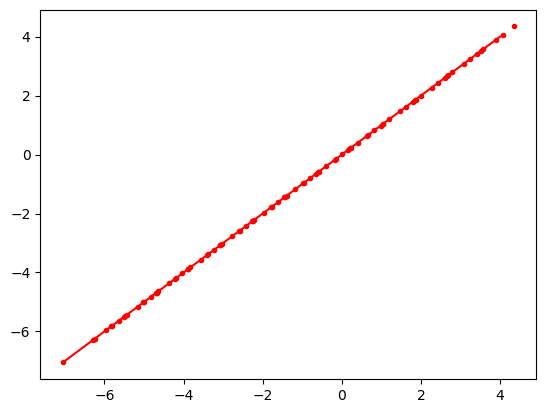

In [14]:
theirname='logS6+/S2- (T&W26)_PTerm'
myname='logS6S2_TW26'
plt.plot(df[theirname], bench[myname], '.r')
import Thermobar as pt
plt.plot([-7, 4], [-7, 4], '-r')
pt.calculate_R2(df[theirname], bench[myname])



## MC25 prssure term

{'R2': 1.0,
 'RMSE': 0.00023,
 'RMSE_num': 0.00023118338833272032,
 'P_val': 0.0,
 'Median': 0.0,
 'Mean': 4e-05,
 'Int': array([3.47349545e-05]),
 'Grad': array([1.00001346]),
 'Grad_err': 6e-05,
 'x_pred': array([[3.09920094e-06],
        [2.01052837e-05],
        [1.30923360e-04],
        [8.55562682e-04],
        [5.59246468e-03],
        [3.57702586e-02],
        [1.97269702e-01],
        [6.20414303e-01],
        [9.16030973e-01],
        [9.86491129e-01],
        [9.97962777e-01],
        [9.99696140e-01],
        [9.99954754e-01],
        [1.56130903e-06],
        [9.95782052e-06],
        [6.36043907e-05],
        [4.06816078e-04],
        [2.60166658e-03],
        [1.64718291e-02],
        [9.72420795e-02],
        [4.09664960e-01],
        [8.17432632e-01],
        [9.66583456e-01],
        [9.94682124e-01],
        [9.99174411e-01],
        [9.99872343e-01],
        [1.11202397e-06],
        [6.95560298e-06],
        [4.34602755e-05],
        [2.71214806e-04],
        [1.68

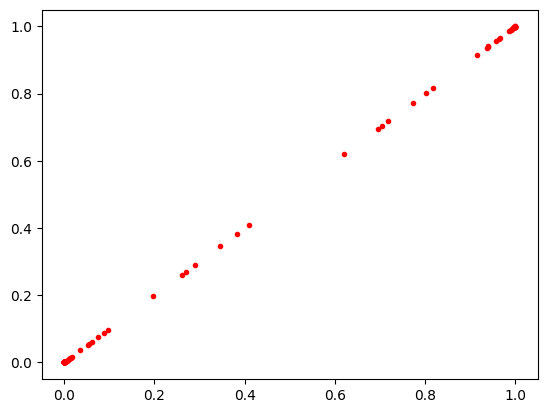

In [15]:
theirname='S6+/ΣS (M&C25)_Pterm'
myname='S6St_MC25'
plt.plot(df[theirname], bench[myname], '.r')
import Thermobar as pt
#plt.plot([-7, 4], [-7, 4], '-r')
pt.calculate_R2(df[theirname], bench[myname])



{'R2': 1.0,
 'RMSE': 0.00121,
 'RMSE_num': 0.0012107249832148217,
 'P_val': 0.0,
 'Median': 0.00058,
 'Mean': 0.00063,
 'Int': array([0.00053996]),
 'Grad': array([0.99991937]),
 'Grad_err': 4e-05,
 'x_pred': array([[-5.50874892],
        [-4.69668106],
        [-3.88292599],
        [-3.06737644],
        [-2.24996116],
        [-1.43065844],
        [-0.60950927],
        [ 0.21337196],
        [ 1.03779104],
        [ 1.86347412],
        [ 2.6900757 ],
        [ 3.51719472],
        [ 4.34439754],
        [-5.80651045],
        [-5.00183138],
        [-4.19648528],
        [-3.39042518],
        [-2.583617  ],
        [-1.77604498],
        [-0.96771707],
        [-0.15866974],
        [ 0.65102881],
        [ 1.46127783],
        [ 2.27194613],
        [ 3.08287763],
        [ 3.89389986],
        [-5.95388537],
        [-5.15766219],
        [-4.36188865],
        [-3.5665688 ],
        [-2.77169141],
        [-1.97722738],
        [-1.18312841],
        [-0.38932709],
        [ 

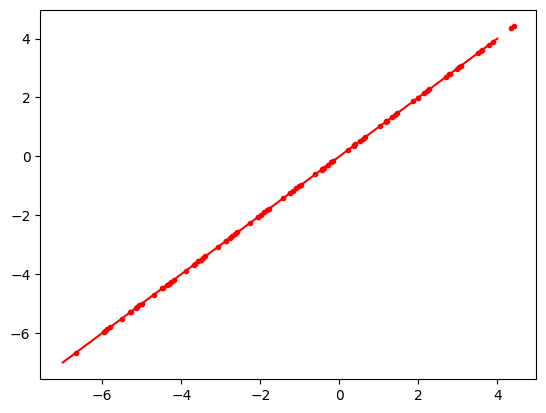

In [16]:
theirname='logS6+/S2- (M&C25)_Pterm'
myname='logS6S2_MC25'
plt.plot(df[theirname], bench[myname], '.r')
import Thermobar as pt
plt.plot([-7, 4], [-7, 4], '-r')
pt.calculate_R2(df[theirname], bench[myname])



## BoW 23

{'R2': 1.0,
 'RMSE': 0.00121,
 'RMSE_num': 0.0012058757474165168,
 'P_val': 0.0,
 'Median': 0.00064,
 'Mean': 0.00067,
 'Int': array([0.00058826]),
 'Grad': array([0.99994448]),
 'Grad_err': 4e-05,
 'x_pred': array([[-5.50878958],
        [-4.69672173],
        [-3.88296666],
        [-3.06741711],
        [-2.25000182],
        [-1.43069911],
        [-0.60954993],
        [ 0.2133313 ],
        [ 1.03775037],
        [ 1.86343345],
        [ 2.69003503],
        [ 3.51715406],
        [ 4.34435688],
        [-5.80655112],
        [-5.00187205],
        [-4.19652594],
        [-3.39046584],
        [-2.58365767],
        [-1.77608564],
        [-0.96775773],
        [-0.15871041],
        [ 0.65098815],
        [ 1.46123716],
        [ 2.27190546],
        [ 3.08283697],
        [ 3.89385919],
        [-5.95392603],
        [-5.15770286],
        [-4.36192932],
        [-3.56660947],
        [-2.77173207],
        [-1.97726805],
        [-1.18316907],
        [-0.38936775],
        [ 

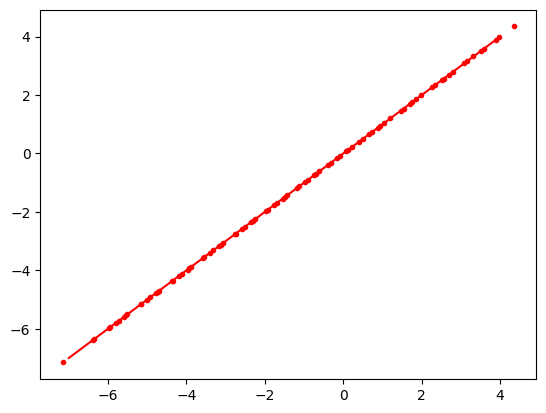

In [17]:
theirname='logS6+/S2- (B&W23)_Pterm'
myname='logS6S2_BW23'
plt.plot(df[theirname], bench[myname], '.r')
import Thermobar as pt
plt.plot([-7, 4], [-7, 4], '-r')
pt.calculate_R2(df[theirname], bench[myname])



{'R2': 1.0,
 'RMSE': 0.00023,
 'RMSE_num': 0.00023231232462109108,
 'P_val': 0.0,
 'Median': 0.0,
 'Mean': 4e-05,
 'Int': array([3.13512622e-05]),
 'Grad': array([1.00002355]),
 'Grad_err': 6e-05,
 'x_pred': array([[3.09891076e-06],
        [2.01034012e-05],
        [1.30911104e-04],
        [8.55482643e-04],
        [5.59194399e-03],
        [3.57670292e-02],
        [1.97254875e-01],
        [6.20392252e-01],
        [9.16023771e-01],
        [9.86489881e-01],
        [9.97962586e-01],
        [9.99696112e-01],
        [9.99954749e-01],
        [1.56116284e-06],
        [9.95688817e-06],
        [6.35984357e-05],
        [4.06778003e-04],
        [2.60142361e-03],
        [1.64703122e-02],
        [9.72338600e-02],
        [4.09642316e-01],
        [8.17418657e-01],
        [9.66580432e-01],
        [9.94681629e-01],
        [9.99174334e-01],
        [9.99872331e-01],
        [1.11191985e-06],
        [6.95495173e-06],
        [4.34562065e-05],
        [2.71189419e-04],
        [1.68

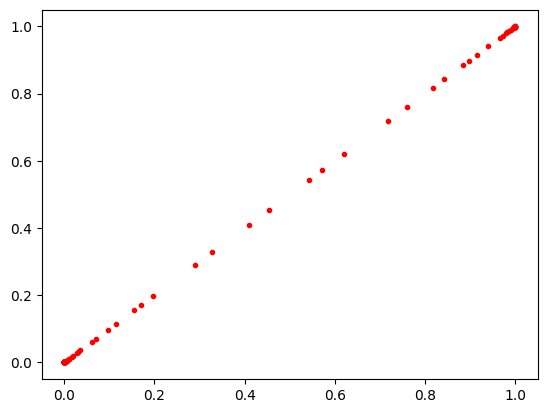

In [18]:
theirname='S6+/ΣS (B&W23)_Pterm'
myname='S6St_BW23'
plt.plot(df[theirname], bench[myname], '.r')
import Thermobar as pt
#plt.plot([-7, 4], [-7, 4], '-r')
pt.calculate_R2(df[theirname], bench[myname])



## 1 atmosphere calcs

{'R2': 1.0,
 'RMSE': 0.00023,
 'RMSE_num': 0.00022941374748668218,
 'P_val': 0.0,
 'Median': 0.0,
 'Mean': 4e-05,
 'Int': array([3.98735259e-05]),
 'Grad': array([1.0000044]),
 'Grad_err': 5e-05,
 'x_pred': array([[3.09955912e-06],
        [2.01076072e-05],
        [1.30938489e-04],
        [8.55661475e-04],
        [5.59310740e-03],
        [3.57742447e-02],
        [1.97288003e-01],
        [6.20441518e-01],
        [9.16039862e-01],
        [9.86492669e-01],
        [9.97963012e-01],
        [9.99696175e-01],
        [9.99954759e-01],
        [1.56148947e-06],
        [9.95897134e-06],
        [6.36117410e-05],
        [4.06863075e-04],
        [2.60196647e-03],
        [1.64737014e-02],
        [9.72522249e-02],
        [4.09692908e-01],
        [8.17449877e-01],
        [9.66587189e-01],
        [9.94682736e-01],
        [9.99174507e-01],
        [9.99872358e-01],
        [1.11215249e-06],
        [6.95640684e-06],
        [4.34652980e-05],
        [2.71246142e-04],
        [1.688

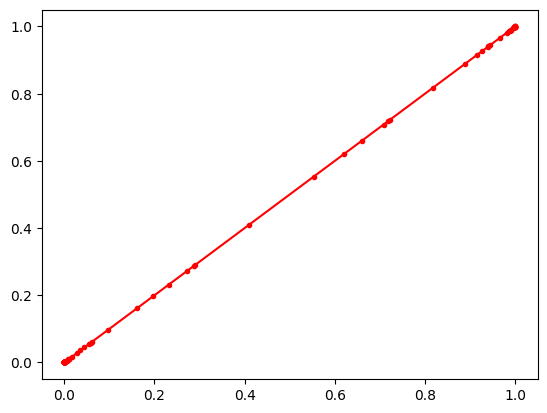

In [19]:

plt.plot(df['S6+/ΣS_1atm'], bench['S6St_1atm'], '.r')
import Thermobar as pt
plt.plot([0, 1], [0, 1], '-r')
pt.calculate_R2(df['S6+/ΣS_1atm'], bench['S6St_1atm'])



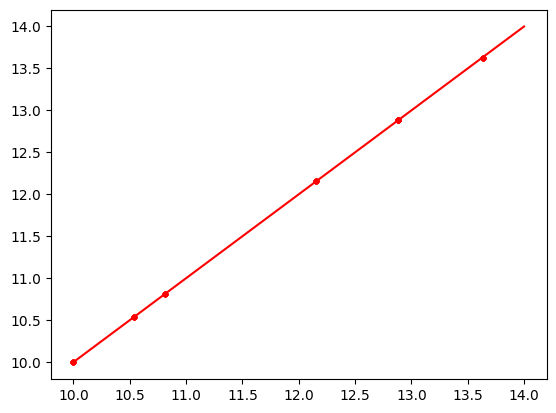

In [20]:
plt.plot(df['logCs6+_1atm'], bench['LogCS6_1atm'], '.r')
import Thermobar as pt
pt.calculate_R2(df['logCs2-_1atm'], bench['LogCs2_1atm'])
plt.plot([10, 14], [10, 14], '-r')


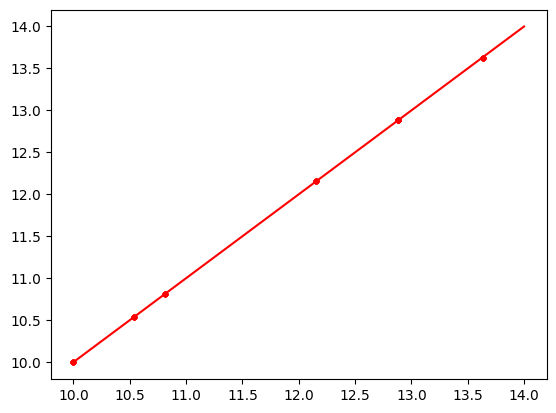

In [21]:
plt.plot(df['logCs6+_1atm'], bench['LogCS6_1atm'], '.r')
import Thermobar as pt
pt.calculate_R2(df['logCs6+_1atm'], bench['LogCS6_1atm'])
plt.plot([10, 14], [10, 14], '-r')
